# Diffusion Concept Demo
### Forward Diffusion, Noise Prediction, and Reverse Intuition

This demo focuses on

- how noise is gradually added to images
- how a noisy image can be sampled at any timestep
- why diffusion models predict **noise**
- what the model input/output looks like

We use **FashionMNIST** dataset which contains 10 clothing classes and have 60k training 28x28 greayscale images. The images can eb of a T-shirt, coat, bag or sneaker etc.



In [1]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

## 1. Device

We use GPU if available, otherwise CPU.

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


## 2. Load FashionMNIST

We load the FashionMNIST dataset, which contains small clothing images. These images will be our starting point for the diffusion process.

Each image has shape $1 \times 28 \times 28$.

We normalize images so pixel values range from -1 to 1 instead of 0 to 1. Neural networks train more stably when inputs are centered around zero.

In [3]:
#We normalize images so pixel values range from -1 to 1 instead of 0 to 1.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))   # map [0,1] -> [-1,1]
])

In [4]:
dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

In [5]:
#The DataLoader feeds images to the model in batches of 32.
loader = DataLoader(dataset, batch_size=32, shuffle=True)

In [6]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

In [7]:
#Moves tensors to the same device as the model.
images, labels = next(iter(loader))
images = images.to(device)

#32 images, 1 channel(grayscale), 28x28 pixels
print("Batch shape:", images.shape)

Batch shape: torch.Size([32, 1, 28, 28])


## 3. Utility function for display

The dataset was normalized to `[-1, 1]`.

For plotting, it is easier to map values back to `[0, 1]`.

In [8]:
def denorm(x):
    return (x.clamp(-1, 1) + 1) / 2

## 4. Diffusion schedule

We define a simple linear noise schedule with:

- total diffusion steps: $T = 100$
- $\beta_t$ increasing linearly from $0.0001$ to $0.02$

Then we define:


$$\alpha_t = 1 - \beta_t$$

$$\bar{\alpha}_t = \prod_{i=1}^t \alpha_i$$

### Intuition
- $β_t$ controls how much noise is added at each step
- $α_t$ controls how much signal remains at each step
- $ᾱ_t$ tells us how much of the original image remains after many steps

his code defines the noise schedule for the diffusion process. It creates a sequence of noise values 𝛽𝑡 that gradually increase from 0.0001 to 0.02 over 100 steps, meaning we add a little more noise at each step. Using these values, the code computes
$$\alpha_t = 1 - \beta_t$$

to represent how much of the original image signal remains, and then calculates the cumulative product $\bar{\alpha}_t$, which tells us how much of the original image survives after multiple steps of noise. The square root terms are precomputed so they can be easily used later to generate noisy images during the diffusion process

In [9]:
#total number of diffusion steps
T = 100

In [10]:
#the noise schedule range
beta_start = 0.0001
beta_end = 0.02

#noise schedule where noise gradually increases across diffusion steps.
betas = torch.linspace(beta_start, beta_end, T, device=device)   # [T]

In [11]:
# beta  = how much noise we add
# alpha = how much of the original signal we keep.
alphas = 1.0 - betas                                             # [T]
alpha_bars = torch.cumprod(alphas, dim=0)                        # [T]

In [12]:
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

In [13]:
print("betas shape:", betas.shape)
print("alphas shape:", alphas.shape)
print("alpha_bars shape:", alpha_bars.shape)

betas shape: torch.Size([100])
alphas shape: torch.Size([100])
alpha_bars shape: torch.Size([100])


## 5. Visualize the noise schedule

These plots show:

- `β_t`: noise added per step
- `α_t`: signal retained per step
- `ᾱ_t`: cumulative signal remaining

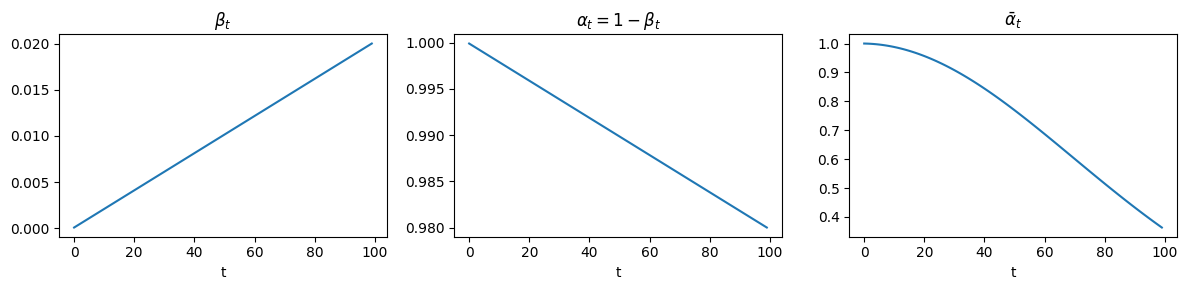

In [14]:
plt.figure(figsize=(12, 3))

plt.subplot(1, 3, 1)
plt.plot(betas.cpu().numpy())
plt.title(r"$\beta_t$")
plt.xlabel("t")

plt.subplot(1, 3, 2)
plt.plot(alphas.cpu().numpy())
plt.title(r"$\alpha_t = 1-\beta_t$")
plt.xlabel("t")

plt.subplot(1, 3, 3)
plt.plot(alpha_bars.cpu().numpy())
plt.title(r"$\bar{\alpha}_t$")
plt.xlabel("t")

plt.tight_layout()
plt.show()

## 6. Closed-form forward diffusion

Instead of adding noise step-by-step, we can directly sample a noisy version of the clean image at timestep $t$ using:

$$x_t = \sqrt{\bar{\alpha_t}}x_0 + \sqrt{1 - \bar{\alpha_t}} ϵ$$

where
$$\epsilon \sim \mathcal{N}(0, 1)$$


### Important idea
This means we can jump directly from clean image $x_0$ to noisy image $x_t$ for any timestep $t$.

The equation simply says noisy image = (some amount of original image) + (some amount of noise)

the coefficients control the balance.

This function generates a noisy version of a clean image at a specific diffusion timestep $t$. Instead of adding noise step-by-step, it uses the closed-form diffusion equation to directly compute $x_t$ from the original image $x_0$. It samples random Gaussian noise and mixes it with the image using precomputed coefficients $\sqrt{\bar{\alpha_t}}$ and $\sqrt{1 - \bar{\alpha_t}}$. The function returns the noisy image $x_t$ and the noise that was added, which the model will later learn to predict.

In [15]:
def q_sample(x0, t, noise=None):
    """
    Sample x_t directly from x_0 using the forward diffusion formula.

    Args:
        x0:    [B, 1, 28, 28] // clean image batch
        t:     [B] integer timesteps in [0, T-1]
        noise: optional Gaussian noise of same shape as x0

    Returns:
        xt:    noisy image at timestep t
        noise: sampled Gaussian noise
    """
    #generate random gaussian noise with the same shape as img.
    if noise is None:
        noise = torch.randn_like(x0)

    #.view(-1,1,1,1) reshapes it so it can braodcast across the image tensor.
    sqrt_ab = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    sqrt_1mab = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)

    xt = sqrt_ab * x0 + sqrt_1mab * noise
    return xt, noise

## 7. Visualize one image across timesteps

We take one FashionMNIST image and show how it becomes noisier over time.

Expected progression:

- early timestep → mostly clean
- mid timestep → partially corrupted
- late timestep → nearly pure noise

This code visualizes the forward diffusion process on one sample image from the dataset. It selects a single image and generates noisy versions at different timesteps using the q_sample() function. Each subplot shows how the image becomes progressively noisier as
𝑡 increases. This helps students see how diffusion gradually destroys the original image until it becomes mostly noise.

In [16]:
sample = images[0:1]
sample_label = labels[0].item()

In [17]:
timesteps = [0, 9, 29, 59, 99]

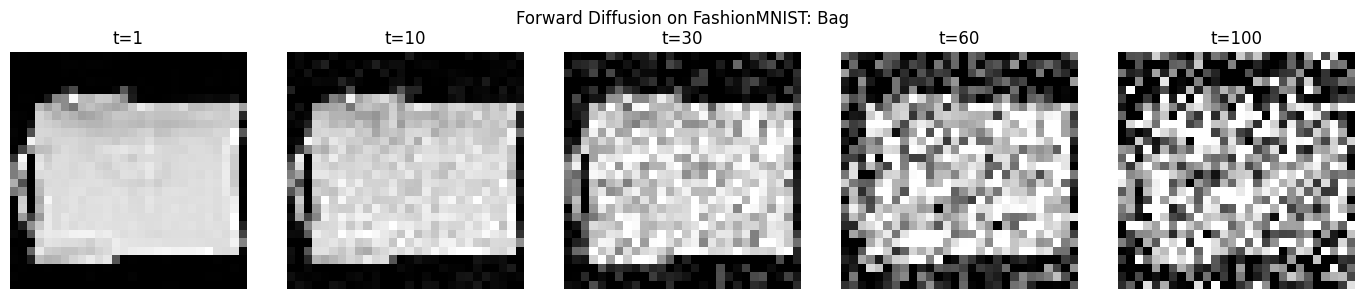

In [18]:
fig, axes = plt.subplots(1, len(timesteps), figsize=(14, 3))
for ax, t in zip(axes, timesteps):
    t_tensor = torch.tensor([t], device=device)
    xt, _ = q_sample(sample, t_tensor)
    ax.imshow(denorm(xt[0, 0]).detach().cpu(), cmap="gray")
    ax.set_title(f"t={t+1}")
    ax.axis("off")

plt.suptitle(f"Forward Diffusion on FashionMNIST: {class_names[sample_label]}")
plt.tight_layout()
plt.show()

## 8. What is the model trying to predict?

A diffusion model is trained to predict the noise that was added.

To make that intuition clearer, we show:

- the clean image $x_0$
- the noisy image $x_t$
- the true sampled noise $\epsilon$

at a few different timesteps.


This code shows how diffusion corrupts an image with noise. For a few different timesteps, it displays three images: the original clean image, the noisy version of the image at that timestep, and the random noise that was added. As the timestep increases, the noisy image looks more and more like pure noise. This helps visualize how diffusion gradually destroys the image by mixing it with random noise.

In [19]:
compare_timesteps = [4, 49, 94]

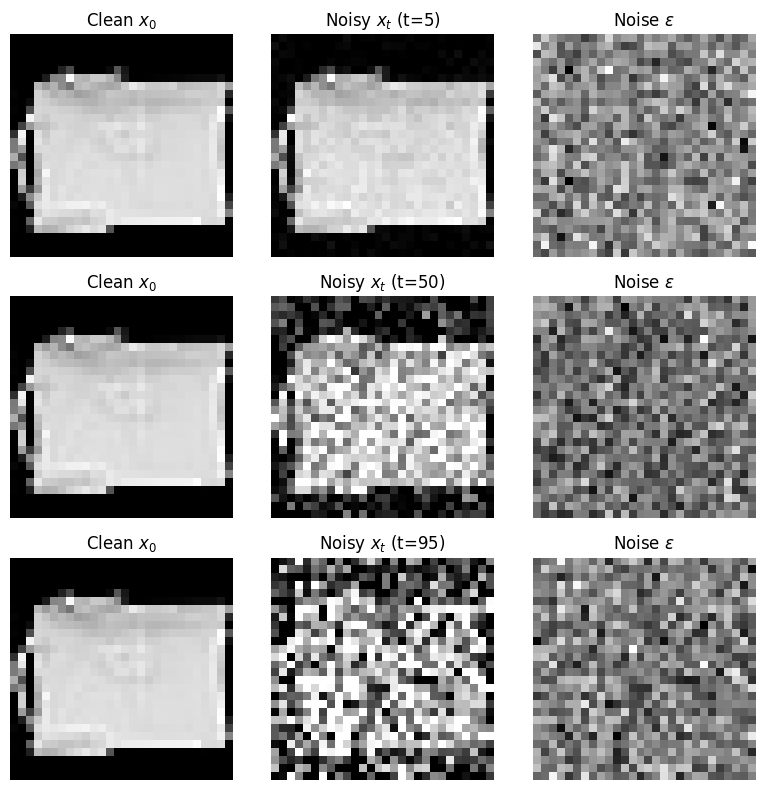

In [20]:
fig, axes = plt.subplots(len(compare_timesteps), 3, figsize=(8, 8))

for row, t in enumerate(compare_timesteps):
    t_tensor = torch.tensor([t], device=device)
    xt, eps = q_sample(sample, t_tensor)

    axes[row, 0].imshow(denorm(sample[0, 0]).detach().cpu(), cmap="gray")
    axes[row, 0].set_title("Clean $x_0$")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(denorm(xt[0, 0]).detach().cpu(), cmap="gray")
    axes[row, 1].set_title(f"Noisy $x_t$ (t={t+1})")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(eps[0, 0].detach().cpu(), cmap="gray")
    axes[row, 2].set_title("Noise $\\epsilon$")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.show()

## 9. Key DDPM idea: if we know the noise, we can recover the clean image

Starting from the forward diffusion equation:

$$x_t = \sqrt{\bar{\alpha_t}}x_0 + \sqrt{1 - \bar{\alpha_t}} ϵ$$

we can rearrange to recover the clean image:

$$x_0 = \frac{x_t - \sqrt{1 - \bar{\alpha_t}} ϵ}{\sqrt{\bar{\alpha_t}}}$$

### Core lesson
If the model can predict the noise well, then it can help us reconstruct the original image.

This code shows an important DDPM idea: if we know the exact noise that was added, we can recover the original clean image. The function `recover_x0_from_noise` uses the diffusion formula rearranged to estimate $x_0$ from the noisy image $x_t$ and the true noise $\epsilon$.

Then the code picks one timestep, creates a noisy image, reconstructs the clean image, and plots all three: original, noisy, and recovered. The main takeaway for students is that the model's job is to predict the noise well, because once the noise is known, the clean image can be reconstructed.

In [21]:
def recover_x0_from_noise(xt, t, eps):
    """
    Recover x_0 from x_t if the true epsilon is known.
    """
    sqrt_ab = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    sqrt_1mab = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)

    x0_hat = (xt - sqrt_1mab * eps) / sqrt_ab
    return x0_hat

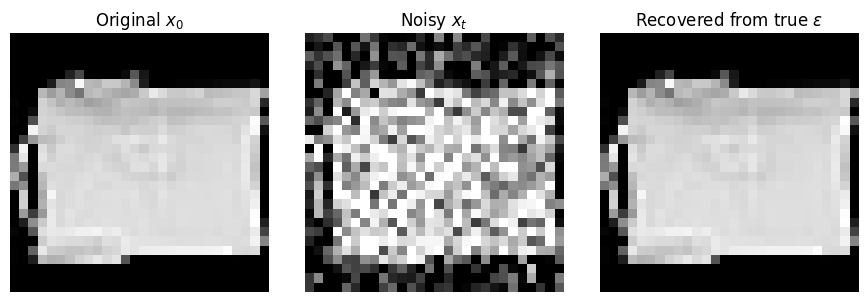

In [22]:
t_demo = torch.tensor([59], device=device)

xt_demo, eps_demo = q_sample(sample, t_demo)
x0_hat_demo = recover_x0_from_noise(xt_demo, t_demo, eps_demo)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))

axes[0].imshow(denorm(sample[0, 0]).detach().cpu(), cmap="gray")
axes[0].set_title("Original $x_0$")
axes[0].axis("off")

axes[1].imshow(denorm(xt_demo[0, 0]).detach().cpu(), cmap="gray")
axes[1].set_title("Noisy $x_t$")
axes[1].axis("off")

axes[2].imshow(denorm(x0_hat_demo[0, 0]).detach().cpu(), cmap="gray")
axes[2].set_title("Recovered from true $\\epsilon$")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## 10. How do we train the model to learn the noise

During training, each image is paired with:

- a randomly sampled timestep $t$
- a noisy version $x_t$
- the true noise $\epsilon$

So the model learns the mapping:

$$(x_t, t) \rightarrow \epsilon$$

This is the core DDPM training setup.

In [23]:
batch_x0, batch_y = next(iter(loader))
batch_x0 = batch_x0.to(device)

t = torch.randint(0, T, (batch_x0.size(0),), device=device)
xt, eps = q_sample(batch_x0, t)

print("x0 shape:", batch_x0.shape)
print("xt shape:", xt.shape)
print("eps shape:", eps.shape)
print("t shape:", t.shape)

x0 shape: torch.Size([32, 1, 28, 28])
xt shape: torch.Size([32, 1, 28, 28])
eps shape: torch.Size([32, 1, 28, 28])
t shape: torch.Size([32])


## 11. Timestep embedding

The model must know **which timestep** a noisy image comes from.

We encode timestep $t$ into a vector using a sinusoidal embedding, similar in spirit to positional encodings in transformers.

The model must know how noisy the image is in order to remove the noise correctly. Since neural networks cannot easily use raw integers like timestep values, we convert the timestep into a vector using a sinusoidal embedding. This embedding gives the model information about the diffusion step in a smooth numerical form.

In [24]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        """
        Sinusoidal timestep embedding

        Args:
            t: [B]

        Returns:
            emb: [B, dim]
        """
        half = self.dim // 2
        freqs = torch.exp(
            -math.log(10000) * torch.arange(0, half, device=t.device).float() / half
        )
        angles = t.float().unsqueeze(1) * freqs.unsqueeze(0)
        emb = torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)
        return emb

## 12. Tiny noise-prediction CNN

This is a very small demonstration model.

### Input
- noisy image $x_t$
- timestep $t$

### Output
- predicted noise $\epsilon$

This CNN takes a noisy image and the timestep as input and predicts the noise that was added to the image. The timestep is converted into an embedding and injected into the network so the model knows how noisy the image is. During training, the predicted noise is compared with the true noise, and the model learns to estimate it accurately.

In [25]:
class MiniDenoiser(nn.Module):
    def __init__(self, time_dim=32):
        super().__init__()

        self.time_mlp = nn.Sequential(
            TimeEmbedding(time_dim),
            nn.Linear(time_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64)
        )

        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 1, kernel_size=3, padding=1)

        self.act = nn.ReLU()

    def forward(self, x, t):
        """
        Args:
            x: [B, 1, 28, 28]
            t: [B]

        Returns:
            predicted noise: [B, 1, 28, 28]
        """
        temb = self.time_mlp(t).view(-1, 64, 1, 1)

        h = self.act(self.conv1(x))
        h = self.act(self.conv2(h))

        # inject timestep information
        h = h + temb

        out = self.conv3(h)

        return out

In [26]:
model = MiniDenoiser().to(device)
print(model)

MiniDenoiser(
  (time_mlp): Sequential(
    (0): TimeEmbedding()
    (1): Linear(in_features=32, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=64, bias=True)
  )
  (conv1): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act): ReLU()
)


## 13. One forward pass

We now simulate one training step:

1. sample noisy images $x_t$
2. pass $(x_t, t)$ through the model
3. compare predicted noise with true noise using MSE

The DDPM training objective is:

$$L = MSE(\epsilon, \epsilon_0(x_t, t))$$

This block only simulates one forward pass to demonstrate the DDPM training objective. We generate noisy images, predict the noise using the model, and compute the loss. In a real training setup, this process would run inside loops over many batches and many epochs so the model can gradually learn to predict the noise accurately.

In [27]:
demo_batch = batch_x0[:8]
demo_t = torch.randint(0, T, (8,), device=device)

In [28]:
demo_xt, demo_eps = q_sample(demo_batch, demo_t)

In [29]:
pred_eps = model(demo_xt, demo_t)
loss = nn.MSELoss()(pred_eps, demo_eps)

print("pred_eps shape:", pred_eps.shape)
print("demo loss:", loss.item())

pred_eps shape: torch.Size([8, 1, 28, 28])
demo loss: 1.0466055870056152


## 14. Visualize clean / noisy / true noise / predicted noise

This helps connect the training objective to what the network is learning.

The model is not directly predicting the image.

It is predicting the **noise pattern**.

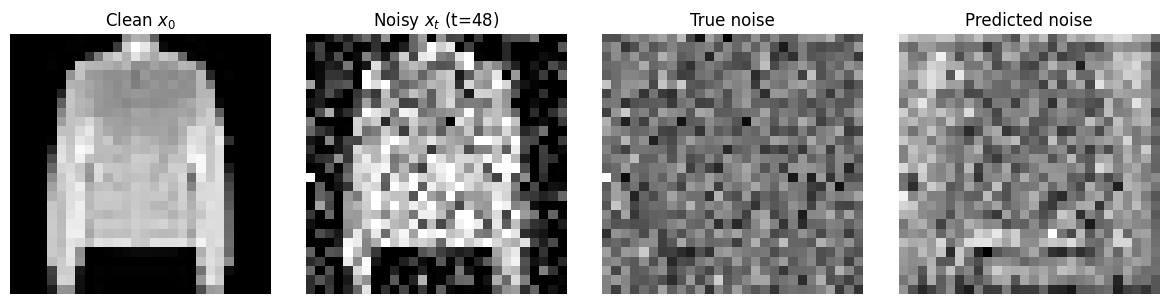

In [30]:
idx = 0

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

axes[0].imshow(denorm(demo_batch[idx, 0]).detach().cpu(), cmap="gray")
axes[0].set_title("Clean $x_0$")
axes[0].axis("off")

axes[1].imshow(denorm(demo_xt[idx, 0]).detach().cpu(), cmap="gray")
axes[1].set_title(f"Noisy $x_t$ (t={demo_t[idx].item()+1})")
axes[1].axis("off")

axes[2].imshow(demo_eps[idx, 0].detach().cpu(), cmap="gray")
axes[2].set_title("True noise")
axes[2].axis("off")

axes[3].imshow(pred_eps[idx, 0].detach().cpu(), cmap="gray")
axes[3].set_title("Predicted noise")
axes[3].axis("off")

plt.tight_layout()
plt.show()

## 15. Reverse-process intuition only

This is **not actual DDPM reverse sampling**.

It is only a visualization to help students understand the high-level idea:

very noisy image → less noisy image → visible structure → clean image.

We simply plot noisy versions at decreasing timesteps.

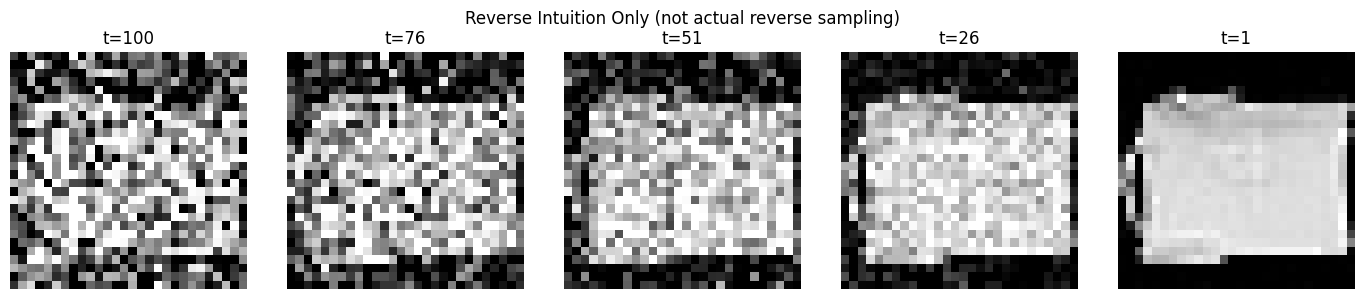

In [31]:
reverse_like_timesteps = [99, 75, 50, 25, 0]

fig, axes = plt.subplots(1, len(reverse_like_timesteps), figsize=(14, 3))
for ax, t_val in zip(axes, reverse_like_timesteps):
    t_tensor = torch.tensor([t_val], device=device)
    xt_vis, _ = q_sample(sample, t_tensor)
    ax.imshow(denorm(xt_vis[0, 0]).detach().cpu(), cmap="gray")
    ax.set_title(f"t={t_val+1}")
    ax.axis("off")

plt.suptitle("Reverse Intuition Only (not actual reverse sampling)")
plt.tight_layout()
plt.show()

## 16. Summary

In this demo we showed:

- how a diffusion noise schedule is defined
- how to sample noisy images directly from clean images
- how image structure disappears over time
- why diffusion models predict noise
- how a tiny denoiser takes $(x_t, t)$ and outputs $\epsilon$
- what reverse-process intuition looks like

### In the assignment
you will implement:

- forward diffusion on MNIST
- training the noise-prediction model
- DDPM reverse sampling
- DDIM sampling
- comparison of DDPM vs DDIM outputs